In [9]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path("/Users/glebsavelev/Desktop/da")
DATA_DIR = PROJECT_DIR / "results" / "data"
TABLES_DIR = PROJECT_DIR / "results" / "tables"

# Завантажуємо навчальні й тестові дані
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
).squeeze("columns")

# Завантажуємо зафіксовані результати валідації
validation_summary = pd.read_csv(
    TABLES_DIR / "model_validation_summary.csv"
)

print("=== Перевірка даних ===")
print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert X_train.columns.tolist() == X_test.columns.tolist()

print("\n=== Вибрані пороги класифікації ===")
print(validation_summary.to_string(index=False))

print("\nДані успішно завантажено.")

=== Перевірка даних ===
Навчальна вибірка: (76916, 8)
Тестова вибірка: (19230, 8)

=== Вибрані пороги класифікації ===
              Model Criterion  Threshold       F1   Recall  Precision
Logistic Regression    Max F1        0.4 0.731746 0.679440   0.792777
      Random Forest    Max F1        0.3 0.807902 0.708180   0.940313
                SVM    Max F1        0.4 0.732721 0.675755   0.800175

Дані успішно завантажено.


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

# 1. Визначаємо групи ознак

categorical_features = [
    "gender",
    "smoking_history"
]

numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

# 2. Обробка числових ознак

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Обробка категоріальних ознак

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 4. Загальна схема попередньої обробки

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# 5. Logistic Regression

lr_final = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# 6. Random Forest

rf_final = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# 7. SVM з калібруванням ймовірностей

svm_final = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", CalibratedClassifierCV(
        estimator=LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ),
        method="sigmoid",
        cv=3
    ))
])

# 8. Збираємо моделі в один словник

models = {
    "Logistic Regression": lr_final,
    "Random Forest": rf_final,
    "SVM": svm_final
}

# 9. Завантажуємо вибрані пороги

thresholds = (
    validation_summary
    .set_index("Model")["Threshold"]
    .to_dict()
)

assert set(models) == set(thresholds)

print("=== Моделі для остаточного тестування ===")

for name in models:
    print(f"{name}: поріг {thresholds[name]:.2f}")

print("\nУсі три моделі успішно налаштовано.")
print("Моделі ще не навчені.")

=== Моделі для остаточного тестування ===
Logistic Regression: поріг 0.40
Random Forest: поріг 0.30
SVM: поріг 0.40

Усі три моделі успішно налаштовано.
Моделі ще не навчені.


In [11]:
from sklearn.base import clone

# Словник для збереження навчених моделей
fitted_models = {}

print("=== Навчання фінальних моделей ===")

for name, model in models.items():

    print(f"\nНавчання: {name}")

    # Створюємо незалежну копію моделі
    fitted_model = clone(model)

    # Навчаємо на ВСІЙ навчальній вибірці
    fitted_model.fit(X_train, y_train)

    # Зберігаємо навчену модель
    fitted_models[name] = fitted_model

    print(f"{name}: навчання завершено.")

print("\n=== Підсумок ===")
print("Успішно навчено моделей:", len(fitted_models))

assert len(fitted_models) == 3

print("Усі три моделі готові до тестування.")

=== Навчання фінальних моделей ===

Навчання: Logistic Regression
Logistic Regression: навчання завершено.

Навчання: Random Forest
Random Forest: навчання завершено.

Навчання: SVM
SVM: навчання завершено.

=== Підсумок ===
Успішно навчено моделей: 3
Усі три моделі готові до тестування.


Крок 4. Остаточне тестування трьох моделей
Тепер використаємо тестову вибірку з 19 230 записів, яку ми відклали ще під час попередньої обробки даних.

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Зберігатимемо результати тестування
test_results = []
test_predictions = {}
test_probabilities = {}

print("=== ФІНАЛЬНЕ ТЕСТУВАННЯ МОДЕЛЕЙ ===")

for name, model in fitted_models.items():

    # Поріг, обраний раніше на валідаційній вибірці
    threshold = float(thresholds[name])

    # Ймовірності позитивного класу
    y_proba = model.predict_proba(X_test)[:, 1]

    # Прогноз із зафіксованим порогом
    y_pred = (y_proba >= threshold).astype(int)

    # Матриця помилок
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # Обчислення метрик
    result = {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "Average_Precision": average_precision_score(
            y_test, y_proba
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    test_results.append(result)

    # Збереження прогнозів для майбутніх графіків
    test_predictions[name] = y_pred
    test_probabilities[name] = y_proba

    print(f"\n=== {name} ===")
    print(f"Threshold: {threshold:.2f}")
    print(f"Accuracy: {result['Accuracy']:.4f}")
    print(f"Precision: {result['Precision']:.4f}")
    print(f"Recall: {result['Recall']:.4f}")
    print(f"F1-score: {result['F1']:.4f}")
    print(f"ROC-AUC: {result['ROC_AUC']:.4f}")
    print(
        "Average Precision:",
        f"{result['Average_Precision']:.4f}"
    )

    print("\nМатриця помилок:")
    print(cm)

# Підсумкова таблиця
test_summary = pd.DataFrame(test_results)

print("\n=== ПІДСУМКОВЕ ПОРІВНЯННЯ ===")

columns = [
    "Model",
    "Threshold",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "Average_Precision",
    "FN",
    "FP"
]

print(
    test_summary[columns]
    .round(4)
    .to_string(index=False)
)

assert len(test_summary) == 3

print("\nТестування трьох моделей завершено.")

=== ФІНАЛЬНЕ ТЕСТУВАННЯ МОДЕЛЕЙ ===

=== Logistic Regression ===
Threshold: 0.40
Accuracy: 0.9565
Precision: 0.8044
Recall: 0.6692
F1-score: 0.7306
ROC-AUC: 0.9599
Average Precision: 0.8174

Матриця помилок:
[[17258   276]
 [  561  1135]]

=== Random Forest ===
Threshold: 0.30
Accuracy: 0.9702
Precision: 0.9383
Recall: 0.7081
F1-score: 0.8071
ROC-AUC: 0.9699
Average Precision: 0.8718

Матриця помилок:
[[17455    79]
 [  495  1201]]

=== SVM ===
Threshold: 0.40
Accuracy: 0.9563
Precision: 0.8051
Recall: 0.6651
F1-score: 0.7284
ROC-AUC: 0.9595
Average Precision: 0.8166

Матриця помилок:
[[17261   273]
 [  568  1128]]

=== ПІДСУМКОВЕ ПОРІВНЯННЯ ===
              Model  Threshold  Precision  Recall     F1  ROC_AUC  Average_Precision  FN  FP
Logistic Regression        0.4     0.8044  0.6692 0.7306   0.9599             0.8174 561 276
      Random Forest        0.3     0.9383  0.7081 0.8071   0.9699             0.8718 495  79
                SVM        0.4     0.8051  0.6651 0.7284   0.9595  

Крок 5 — збереження фінальних результатів і матриць помилок
Тепер збережемо підсумкову таблицю та побудуємо три матриці помилок у вигляді графіків, які можна буде використати в четвертому розділі магістерської.

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Папки для збереження результатів
FIGURES_DIR = PROJECT_DIR / "results" / "figures"
TABLES_DIR = PROJECT_DIR / "results" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# 1. Зберігаємо фінальну таблицю
summary_path = TABLES_DIR / "model_test_summary.csv"

test_summary.to_csv(summary_path, index=False)

print("Фінальну таблицю збережено:")
print(summary_path)

# 2. Будуємо матриці помилок для кожної моделі
file_names = {
    "Logistic Regression": "logistic_regression",
    "Random Forest": "random_forest",
    "SVM": "svm"
}

for name, predictions in test_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Class 0", "Class 1"]
    )

    display_matrix.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix: {name}")
    fig.tight_layout()

    filename = f"confusion_matrix_{file_names[name]}.png"
    filepath = FIGURES_DIR / filename

    fig.savefig(filepath, dpi=300, bbox_inches="tight")
    plt.close(fig)

    print("Збережено:", filename)

print("\nФінальні результати та графіки успішно збережено.")

Фінальну таблицю збережено:
/Users/glebsavelev/Desktop/da/results/tables/model_test_summary.csv
Збережено: confusion_matrix_logistic_regression.png
Збережено: confusion_matrix_random_forest.png
Збережено: confusion_matrix_svm.png

Фінальні результати та графіки успішно збережено.


Очікуваний результат

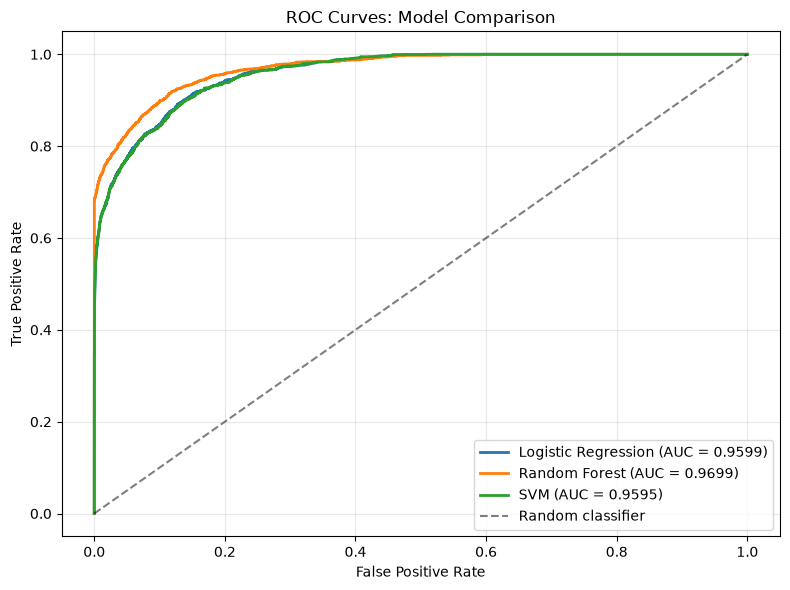

ROC-криві збережено: roc_curves_comparison.png


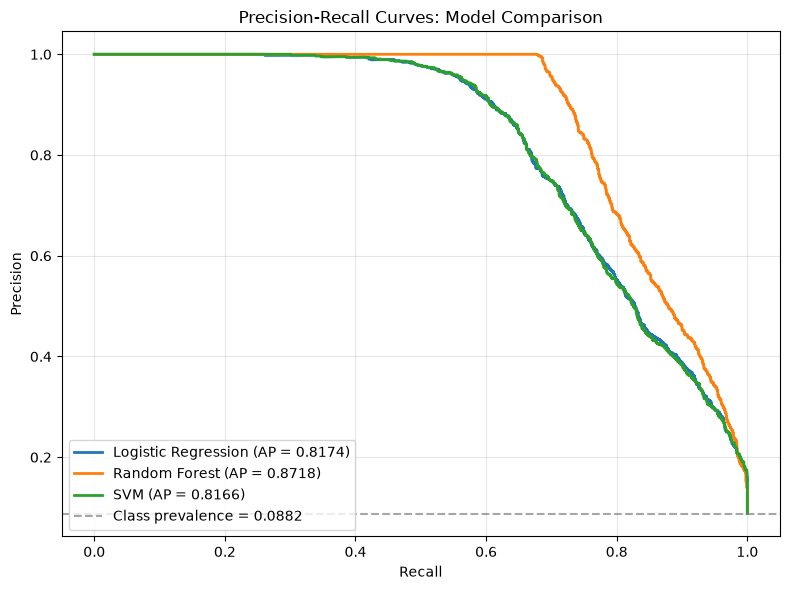

Precision–Recall-криві збережено: precision_recall_curves_comparison.png


In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# 1. ROC-криві
fig, ax = plt.subplots(figsize=(8, 6))

for name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    alpha=0.5,
    label="Random classifier"
)

ax.set_title("ROC Curves: Model Comparison")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

fig.tight_layout()

roc_path = FIGURES_DIR / "roc_curves_comparison.png"
fig.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("ROC-криві збережено:", roc_path.name)


# 2. Precision–Recall-криві
fig, ax = plt.subplots(figsize=(8, 6))

for name, probabilities in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    ap = average_precision_score(
        y_test,
        probabilities
    )

    ax.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {ap:.4f})"
    )

# Частка позитивного класу як базовий орієнтир
positive_rate = y_test.mean()

ax.axhline(
    positive_rate,
    linestyle="--",
    color="gray",
    alpha=0.7,
    label=f"Class prevalence = {positive_rate:.4f}"
)

ax.set_title("Precision-Recall Curves: Model Comparison")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)

fig.tight_layout()

pr_path = FIGURES_DIR / "precision_recall_curves_comparison.png"
fig.savefig(pr_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Precision–Recall-криві збережено:", pr_path.name)

Таблицю з реальними показниками Precision, Recall, F1-score та кількістю помилок FN і FP для всіх трьох моделей із порогом 0,15.

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Пороги, раніше вибрані на валідаційній вибірці
recall_thresholds = {
    "Logistic Regression": 0.15,
    "Random Forest": 0.15,
    "SVM": 0.15
}

recall_results = []

print("=== ТЕСТУВАННЯ МОДЕЛЕЙ З ПІДВИЩЕНИМ RECALL ===")

for name, probabilities in test_probabilities.items():

    threshold = recall_thresholds[name]

    # Використовуємо вже отримані ймовірності
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    result = {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    recall_results.append(result)

    print(f"\n=== {name} ===")
    print(f"Threshold: {threshold:.2f}")
    print(f"Precision: {result['Precision']:.4f}")
    print(f"Recall: {result['Recall']:.4f}")
    print(f"F1-score: {result['F1']:.4f}")
    print(f"FN: {fn}")
    print(f"FP: {fp}")

# Формуємо підсумкову таблицю
recall_test_summary = pd.DataFrame(recall_results)

print("\n=== ПІДСУМКОВА ТАБЛИЦЯ ===")
print(
    recall_test_summary.round(4).to_string(index=False)
)

# Зберігаємо результати
output_path = TABLES_DIR / "model_test_recall80_summary.csv"

recall_test_summary.to_csv(output_path, index=False)

print("\nРезультати збережено:", output_path.name)

=== ТЕСТУВАННЯ МОДЕЛЕЙ З ПІДВИЩЕНИМ RECALL ===

=== Logistic Regression ===
Threshold: 0.15
Precision: 0.5325
Recall: 0.8119
F1-score: 0.6432
FN: 319
FP: 1209

=== Random Forest ===
Threshold: 0.15
Precision: 0.6520
Recall: 0.8119
F1-score: 0.7232
FN: 319
FP: 735

=== SVM ===
Threshold: 0.15
Precision: 0.5368
Recall: 0.8078
F1-score: 0.6450
FN: 326
FP: 1182

=== ПІДСУМКОВА ТАБЛИЦЯ ===
              Model  Threshold  Accuracy  Precision  Recall     F1    TN   FP  FN   TP
Logistic Regression       0.15    0.9205     0.5325  0.8119 0.6432 16325 1209 319 1377
      Random Forest       0.15    0.9452     0.6520  0.8119 0.7232 16799  735 319 1377
                SVM       0.15    0.9216     0.5368  0.8078 0.6450 16352 1182 326 1370

Результати збережено: model_test_recall80_summary.csv


Крок 8 — фінальна перевірка class_weight="balanced"
Це останній основний експеримент із трьома алгоритмами.
Раніше на валідаційній вибірці ми перевірили балансування класів. Тепер потрібно оцінити ті самі стратегії на незалежній тестовій вибірці, щоб порівняти їх із налаштуванням порогу.
Для цього заново навчимо три моделі з class_weight="balanced" на всіх 76 916 навчальних записах. Поріг для них залишимо стандартним — 0.50.

In [16]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

balanced_models = {}
balanced_results = []

# Ті самі алгоритми та гіперпараметри,
# але з балансуванням ваг класів
for name, original_model in models.items():

    print(f"\n=== {name}: Balanced ===")

    model = clone(original_model)

    if name == "SVM":
        model.set_params(
            classifier__estimator__class_weight="balanced"
        )
    else:
        model.set_params(
            classifier__class_weight="balanced"
        )

    # Навчання лише на навчальних даних
    model.fit(X_train, y_train)
    balanced_models[name] = model

    # Оцінка на незалежній тестовій вибірці
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    result = {
        "Model": name,
        "Strategy": "Balanced",
        "Threshold": 0.50,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test, probabilities
        ),
        "Average_Precision": average_precision_score(
            y_test, probabilities
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    balanced_results.append(result)

    print("Accuracy:", round(result["Accuracy"], 4))
    print("Precision:", round(result["Precision"], 4))
    print("Recall:", round(result["Recall"], 4))
    print("F1-score:", round(result["F1"], 4))
    print("ROC-AUC:", round(result["ROC_AUC"], 4))
    print(
        "Average Precision:",
        round(result["Average_Precision"], 4)
    )

    print("\nМатриця помилок:")
    print([[int(tn), int(fp)], [int(fn), int(tp)]])

# Підсумок
balanced_test_summary = pd.DataFrame(balanced_results)

print("\n=== ПІДСУМКИ BALANCED ===")
print(
    balanced_test_summary.round(4).to_string(index=False)
)

# Збереження результатів
output_path = TABLES_DIR / "model_test_balanced_summary.csv"

balanced_test_summary.to_csv(
    output_path,
    index=False
)

print("\nРезультати збережено:", output_path.name)


=== Logistic Regression: Balanced ===
Accuracy: 0.8845
Precision: 0.4251
Recall: 0.8797
F1-score: 0.5732
ROC-AUC: 0.9601
Average Precision: 0.8166

Матриця помилок:
[[15516, 2018], [204, 1492]]

=== Random Forest: Balanced ===
Accuracy: 0.9027
Precision: 0.4729
Recall: 0.8992
F1-score: 0.6198
ROC-AUC: 0.9743
Average Precision: 0.8752

Матриця помилок:
[[15834, 1700], [171, 1525]]

=== SVM: Balanced ===
Accuracy: 0.9588
Precision: 0.8604
Recall: 0.6362
F1-score: 0.7315
ROC-AUC: 0.96
Average Precision: 0.8159

Матриця помилок:
[[17359, 175], [617, 1079]]

=== ПІДСУМКИ BALANCED ===
              Model Strategy  Threshold  Accuracy  Precision  Recall     F1  ROC_AUC  Average_Precision    TN   FP  FN   TP
Logistic Regression Balanced        0.5    0.8845     0.4251  0.8797 0.5732   0.9601             0.8166 15516 2018 204 1492
      Random Forest Balanced        0.5    0.9027     0.4729  0.8992 0.6198   0.9743             0.8752 15834 1700 171 1525
                SVM Balanced        0.5  

Крок 9 — створюємо остаточну порівняльну таблицю
Зараз об'єднаємо всі три збережені групи результатів в один CSV-файл. Це буде одна з головних таблиць четвертого розділу магістерської.

In [17]:
import pandas as pd

# Дані вже отримані в попередніх комірках:
# test_summary
# recall_test_summary
# balanced_test_summary

columns = [
    "Model",
    "Threshold",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "FN",
    "FP"
]

# Конфігурації, обрані за максимальним F1
f1_results = test_summary[columns].copy()
f1_results["Strategy"] = "Max F1"

# Конфігурації з вимогою Recall >= 80%
recall80_results = recall_test_summary[columns].copy()
recall80_results["Strategy"] = "Recall >= 80%"

# Конфігурації з балансуванням класів
balanced_comparison = balanced_test_summary[columns].copy()
balanced_comparison["Strategy"] = "Balanced"

# Об'єднуємо всі результати
final_comparison = pd.concat(
    [f1_results, recall80_results, balanced_comparison],
    ignore_index=True
)

# Задаємо порядок моделей і стратегій
model_order = [
    "Logistic Regression",
    "Random Forest",
    "SVM"
]

strategy_order = [
    "Max F1",
    "Recall >= 80%",
    "Balanced"
]

final_comparison["Model"] = pd.Categorical(
    final_comparison["Model"],
    categories=model_order,
    ordered=True
)

final_comparison["Strategy"] = pd.Categorical(
    final_comparison["Strategy"],
    categories=strategy_order,
    ordered=True
)

final_comparison = final_comparison.sort_values(
    ["Model", "Strategy"]
).reset_index(drop=True)

# Перевіряємо повноту порівняння
assert len(final_comparison) == 9
assert final_comparison["FN"].ge(0).all()
assert final_comparison["FP"].ge(0).all()

# Зберігаємо таблицю
output_path = TABLES_DIR / "final_model_comparison.csv"

final_comparison.to_csv(
    output_path,
    index=False
)

print("=== ПІДСУМКОВЕ ПОРІВНЯННЯ 9 КОНФІГУРАЦІЙ ===")

print(
    final_comparison[
        [
            "Model",
            "Strategy",
            "Threshold",
            "Precision",
            "Recall",
            "F1",
            "FN",
            "FP"
        ]
    ].round(4).to_string(index=False)
)

print("\nКількість конфігурацій:", len(final_comparison))
print("Файл збережено:", output_path.name)

=== ПІДСУМКОВЕ ПОРІВНЯННЯ 9 КОНФІГУРАЦІЙ ===
              Model      Strategy  Threshold  Precision  Recall     F1  FN   FP
Logistic Regression        Max F1       0.40     0.8044  0.6692 0.7306 561  276
Logistic Regression Recall >= 80%       0.15     0.5325  0.8119 0.6432 319 1209
Logistic Regression      Balanced       0.50     0.4251  0.8797 0.5732 204 2018
      Random Forest        Max F1       0.30     0.9383  0.7081 0.8071 495   79
      Random Forest Recall >= 80%       0.15     0.6520  0.8119 0.7232 319  735
      Random Forest      Balanced       0.50     0.4729  0.8992 0.6198 171 1700
                SVM        Max F1       0.40     0.8051  0.6651 0.7284 568  273
                SVM Recall >= 80%       0.15     0.5368  0.8078 0.6450 326 1182
                SVM      Balanced       0.50     0.8604  0.6362 0.7315 617  175

Кількість конфігурацій: 9
Файл збережено: final_model_comparison.csv


Крок 10. Побудова підсумкових графіків
Зараз створимо чотири графіки для порівняння всіх дев'яти конфігурацій:
1. Recall — частка правильно виявлених позитивних записів.
2. F1-score — баланс Precision і Recall.
3. FN — кількість пропущених позитивних записів.
4. FP — кількість хибнопозитивних прогнозів.

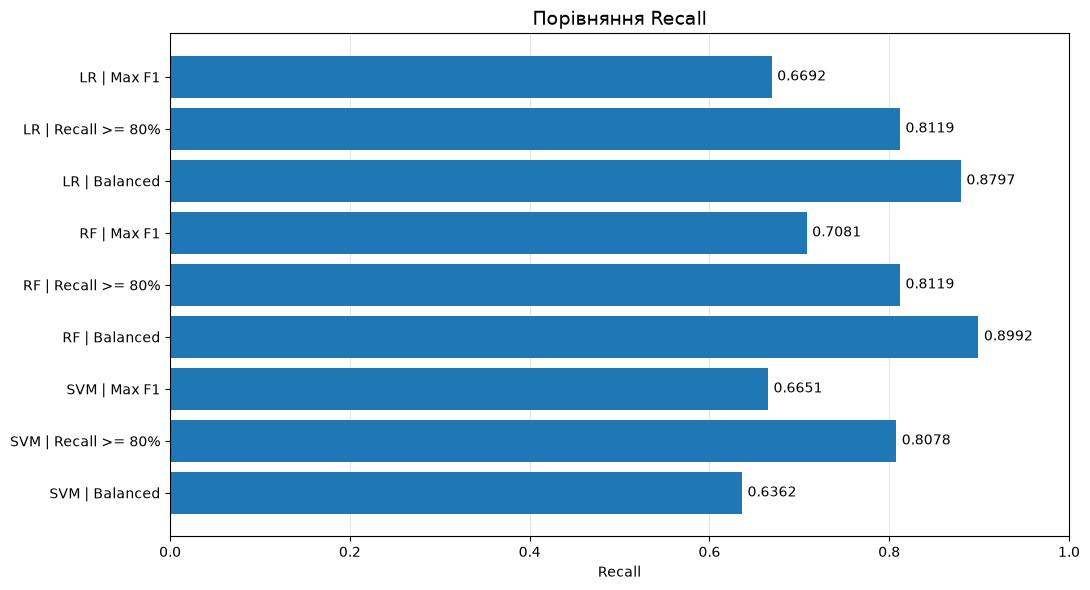

Збережено: final_comparison_recall.png


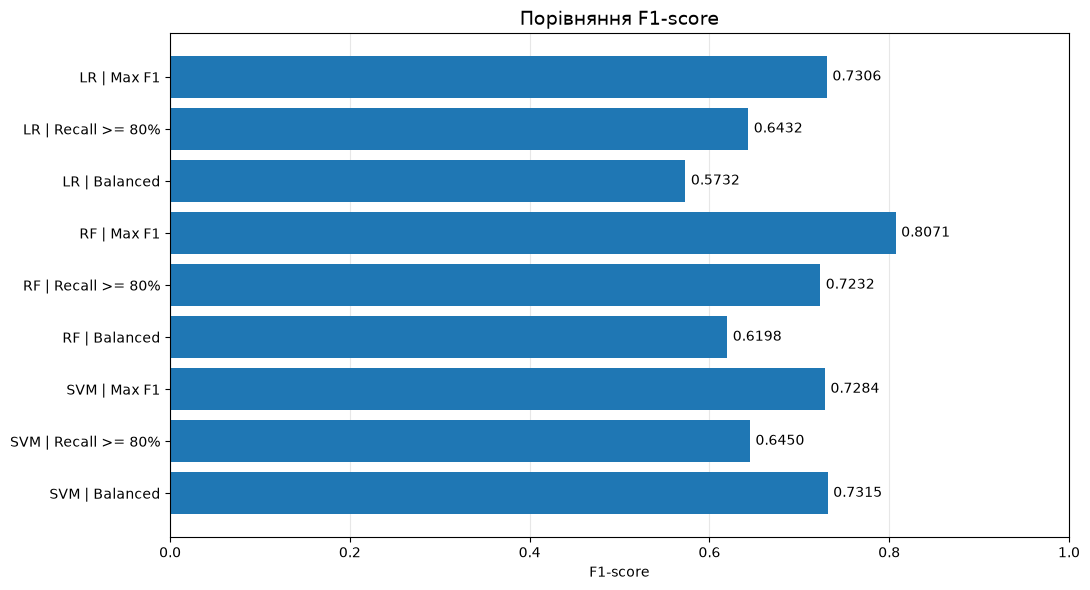

Збережено: final_comparison_f1.png


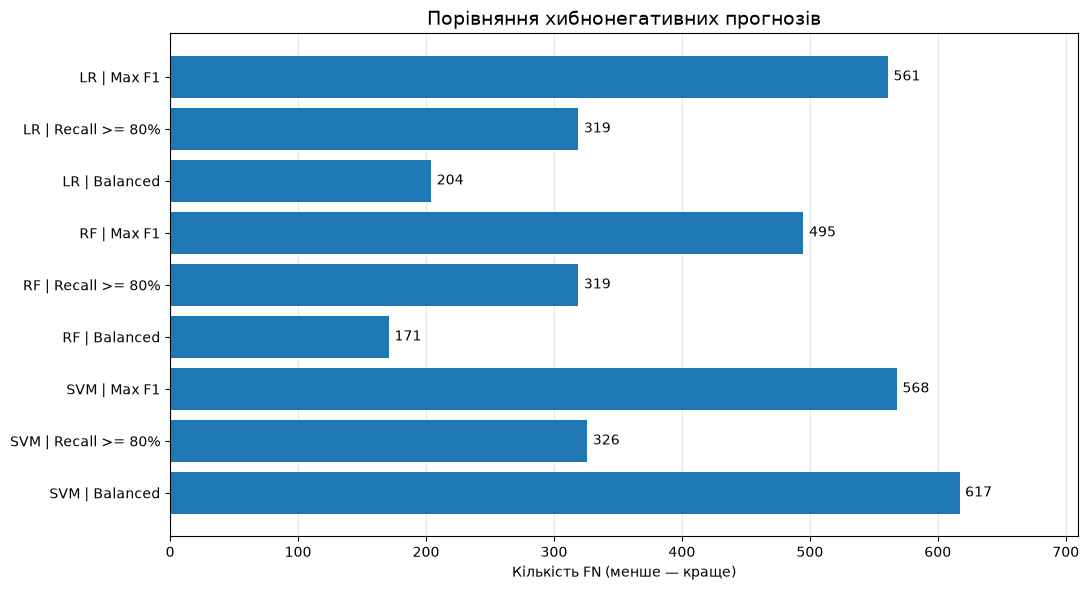

Збережено: final_comparison_fn.png


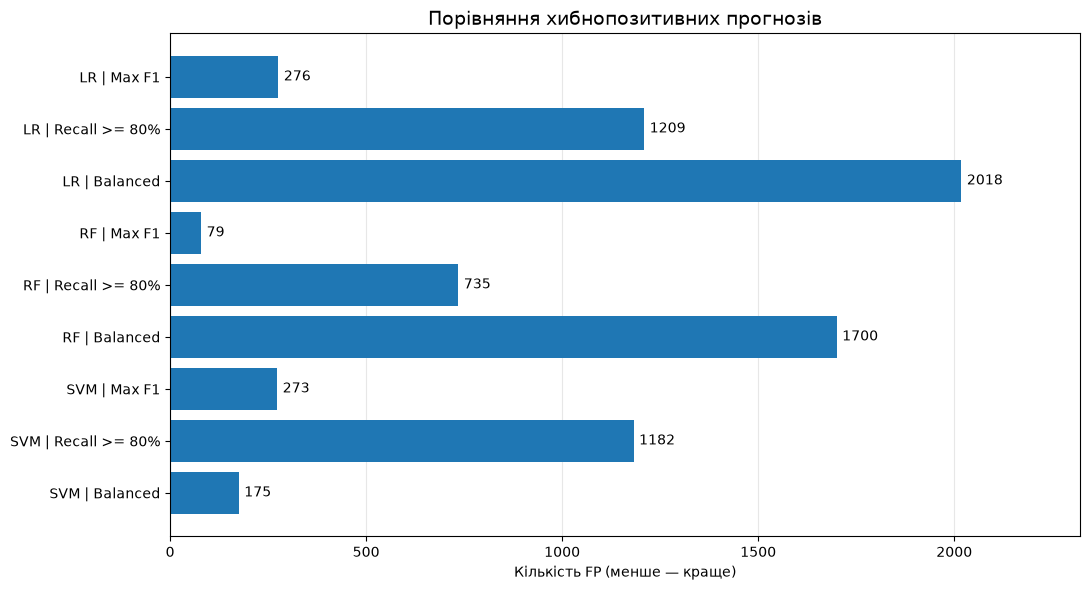

Збережено: final_comparison_fp.png

Усі чотири підсумкові графіки побудовано.


In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Короткі назви моделей
model_short_names = {
    "Logistic Regression": "LR",
    "Random Forest": "RF",
    "SVM": "SVM"
}

# Короткі назви стратегій
strategy_names = {
    "Max F1": "Max F1",
    "Recall >= 80%": "Recall >= 80%",
    "Balanced": "Balanced"
}

# Підписи дев'яти конфігурацій
labels = [
    f"{model_short_names[str(row['Model'])]} | "
    f"{strategy_names[str(row['Strategy'])]}"
    for _, row in final_comparison.iterrows()
]

# Які метрики візуалізуємо
metrics = {
    "Recall": {
        "title": "Порівняння Recall",
        "xlabel": "Recall",
        "filename": "final_comparison_recall.png",
        "max_value": 1.0
    },
    "F1": {
        "title": "Порівняння F1-score",
        "xlabel": "F1-score",
        "filename": "final_comparison_f1.png",
        "max_value": 1.0
    },
    "FN": {
        "title": "Порівняння хибнонегативних прогнозів",
        "xlabel": "Кількість FN (менше — краще)",
        "filename": "final_comparison_fn.png",
        "max_value": None
    },
    "FP": {
        "title": "Порівняння хибнопозитивних прогнозів",
        "xlabel": "Кількість FP (менше — краще)",
        "filename": "final_comparison_fp.png",
        "max_value": None
    }
}

# Будуємо та зберігаємо кожен графік
for metric, settings in metrics.items():

    values = final_comparison[metric].to_numpy()

    fig, ax = plt.subplots(figsize=(11, 6))

    bars = ax.barh(labels, values)

    ax.invert_yaxis()

    ax.set_title(settings["title"], fontsize=14)
    ax.set_xlabel(settings["xlabel"])
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

    if settings["max_value"] is not None:
        ax.set_xlim(0, settings["max_value"])
        ax.bar_label(bars, fmt="%.4f", padding=4)
    else:
        ax.set_xlim(0, max(values) * 1.15)
        ax.bar_label(bars, fmt="%.0f", padding=4)

    fig.tight_layout()

    # Збереження графіка
    output_path = FIGURES_DIR / settings["filename"]

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Збережено:", settings["filename"])

print("\nУсі чотири підсумкові графіки побудовано.")

Крок 11. Автоматична перевірка результатів
Почнемо з першого пункту — він швидкий і не потребує повторного навчання моделей.

In [19]:
import pandas as pd
import numpy as np

# Завантажуємо підсумкову таблицю
comparison = pd.read_csv(
    TABLES_DIR / "final_model_comparison.csv"
)

# Реальна кількість об'єктів кожного класу
n_positive = int((y_test == 1).sum())
n_negative = int((y_test == 0).sum())

print("=== ПЕРЕВІРКА ТЕСТОВОЇ ВИБІРКИ ===")
print("Позитивних записів:", n_positive)
print("Негативних записів:", n_negative)
print("Усього:", len(y_test))

errors = []

# Перевіряємо всі дев'ять конфігурацій
for _, row in comparison.iterrows():

    fn = int(row["FN"])
    fp = int(row["FP"])

    # Відновлюємо TP і TN
    tp = n_positive - fn
    tn = n_negative - fp

    # Повторно розраховуємо метрики
    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    accuracy = (tp + tn) / len(y_test)

    checks = {
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Accuracy": accuracy
    }

    for metric, calculated in checks.items():
        saved = float(row[metric])

        if not np.isclose(
            calculated,
            saved,
            atol=0.0001,
            rtol=0
        ):
            errors.append({
                "Model": row["Model"],
                "Strategy": row["Strategy"],
                "Metric": metric,
                "Saved": saved,
                "Calculated": calculated
            })

    # Перевірка кількості записів
    if min(tn, fp, fn, tp) < 0:
        errors.append({
            "Model": row["Model"],
            "Strategy": row["Strategy"],
            "Metric": "Negative confusion count"
        })

print("\n=== РЕЗУЛЬТАТ ПЕРЕВІРКИ ===")
print("Перевірено конфігурацій:", len(comparison))
print("Знайдено невідповідностей:", len(errors))

if errors:
    print("\nВиявлені проблеми:")
    print(pd.DataFrame(errors).to_string(index=False))
else:
    print("Усі метрики математично узгоджені.")

=== ПЕРЕВІРКА ТЕСТОВОЇ ВИБІРКИ ===
Позитивних записів: 1696
Негативних записів: 17534
Усього: 19230

=== РЕЗУЛЬТАТ ПЕРЕВІРКИ ===
Перевірено конфігурацій: 9
Знайдено невідповідностей: 0
Усі метрики математично узгоджені.


Крок 12. Наскільки результати залежать від HbA1c та рівня глюкози?
У нашому датасеті є дві лабораторні ознаки:
- HbA1c_level — рівень глікованого гемоглобіну.
- blood_glucose_level — рівень глюкози в крові.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import pandas as pd

# 1. Відтворюємо попередній поділ навчальних даних
X_fit_ablation, X_val_ablation, y_fit_ablation, y_val_ablation = (
    train_test_split(
        X_train,
        y_train,
        test_size=0.20,
        stratify=y_train,
        random_state=42
    )
)

# 2. Визначаємо лабораторні ознаки
laboratory_features = [
    "HbA1c_level",
    "blood_glucose_level"
]

numeric_without_labs = [
    col for col in numeric_features
    if col not in laboratory_features
]

# 3. Попередня обробка без лабораторних ознак
preprocessor_without_labs = ColumnTransformer(
    transformers=[
        (
            "numeric",
            clone(numeric_transformer),
            numeric_without_labs
        ),
        (
            "categorical",
            clone(categorical_transformer),
            categorical_features
        )
    ]
)

# 4. Дві конфігурації одного алгоритму
ablation_models = {
    "All 8 features": clone(models["Random Forest"]),

    "Without laboratory features": Pipeline(steps=[
        ("preprocessor", preprocessor_without_labs),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

ablation_results = []

print("=== ABLATION STUDY: RANDOM FOREST ===")
print("Навчальних записів:", len(X_fit_ablation))
print("Валідаційних записів:", len(X_val_ablation))

for name, model in ablation_models.items():

    print(f"\nНавчання: {name}")

    # Для другого експерименту повністю прибираємо
    # лабораторні ознаки з вхідних даних
    if name == "Without laboratory features":
        X_fit_current = X_fit_ablation.drop(
            columns=laboratory_features
        )
        X_val_current = X_val_ablation.drop(
            columns=laboratory_features
        )
    else:
        X_fit_current = X_fit_ablation
        X_val_current = X_val_ablation

    # Навчання лише на X_fit_ablation
    model.fit(X_fit_current, y_fit_ablation)

    # Оцінка лише на X_val_ablation
    probabilities = model.predict_proba(
        X_val_current
    )[:, 1]

    # Однаковий стандартний поріг для обох моделей
    predictions = (probabilities >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_ablation,
        predictions,
        labels=[0, 1]
    ).ravel()

    result = {
        "Feature_Set": name,
        "Number_of_Features": X_fit_current.shape[1],
        "Threshold": 0.50,
        "Accuracy": accuracy_score(
            y_val_ablation, predictions
        ),
        "Precision": precision_score(
            y_val_ablation, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_ablation, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val_ablation, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_val_ablation, probabilities
        ),
        "Average_Precision": average_precision_score(
            y_val_ablation, probabilities
        ),
        "FN": int(fn),
        "FP": int(fp)
    }

    ablation_results.append(result)

# 5. Підсумкова таблиця
ablation_summary = pd.DataFrame(ablation_results)

print("\n=== РЕЗУЛЬТАТИ ABLATION STUDY ===")
print(
    ablation_summary.round(4).to_string(index=False)
)

# 6. Зберігаємо результати
output_path = TABLES_DIR / "ablation_study_results.csv"

ablation_summary.to_csv(output_path, index=False)

print("\nРезультати збережено:", output_path.name)

=== ABLATION STUDY: RANDOM FOREST ===
Навчальних записів: 61532
Валідаційних записів: 15384

Навчання: All 8 features

Навчання: Without laboratory features

=== РЕЗУЛЬТАТИ ABLATION STUDY ===
                Feature_Set  Number_of_Features  Threshold  Accuracy  Precision  Recall     F1  ROC_AUC  Average_Precision   FN  FP
             All 8 features                   8        0.5    0.9707     0.9956  0.6713 0.8019   0.9709             0.8743  446   4
Without laboratory features                   6        0.5    0.9115     0.4875  0.0575 0.1028   0.8270             0.3151 1279  82

Результати збережено: ablation_study_results.csv


Крок 13. Аналіз порогів в абляційному експерименті
Зробимо порівняння для обох наборів ознак за трьома стратегіями:
- Стандартний поріг 0.50.
- Поріг із максимальним F1-score.
- Поріг із найвищим Precision за умови Recall ≥ 80%.

In [22]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

print("=== АНАЛІЗ ПОРОГІВ В ABLATION STUDY ===")

for name, model in ablation_models.items():

    # Обираємо відповідний набір ознак
    if name == "Without laboratory features":
        X_current = X_val_ablation.drop(
            columns=laboratory_features
        )
    else:
        X_current = X_val_ablation

    # Ймовірності позитивного класу
    probabilities = model.predict_proba(X_current)[:, 1]

    # Усі можливі пороги на валідаційних даних
    precision_curve, recall_curve, candidate_thresholds = (
        precision_recall_curve(
            y_val_ablation,
            probabilities
        )
    )

    # Остання точка кривої не має порогу
    p = precision_curve[:-1]
    r = recall_curve[:-1]

    # F1 для кожного порогу
    f1_values = np.divide(
        2 * p * r,
        p + r,
        out=np.zeros_like(p),
        where=(p + r) > 0
    )

    # Поріг із максимальним F1
    best_f1_idx = np.argmax(f1_values)
    best_f1_threshold = candidate_thresholds[best_f1_idx]

    strategies = [
        ("Standard 0.50", 0.50),
        ("Max F1", best_f1_threshold)
    ]

    # Поріг із Recall >= 80%
    valid_indices = np.where(r >= 0.80)[0]

    if len(valid_indices) > 0:
        best_recall_idx = valid_indices[
            np.argmax(p[valid_indices])
        ]

        strategies.append(
            (
                "Recall >= 80%",
                candidate_thresholds[best_recall_idx]
            )
        )

    # Обчислюємо метрики для кожної стратегії
    for strategy, threshold in strategies:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_ablation,
            predictions,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Feature_Set": name,
            "Strategy": strategy,
            "Threshold": float(threshold),
            "Precision": precision_score(
                y_val_ablation, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val_ablation, predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_val_ablation, predictions,
                zero_division=0
            ),
            "FN": int(fn),
            "FP": int(fp)
        })

# Підсумкова таблиця
ablation_threshold_summary = pd.DataFrame(
    threshold_results
)

print("\n=== РЕЗУЛЬТАТИ ===")

print(
    ablation_threshold_summary
    .round(4)
    .to_string(index=False)
)

# Збереження
output_path = (
    TABLES_DIR / "ablation_threshold_analysis.csv"
)

ablation_threshold_summary.to_csv(
    output_path,
    index=False
)

print("\nРезультати збережено:", output_path.name)

=== АНАЛІЗ ПОРОГІВ В ABLATION STUDY ===

=== РЕЗУЛЬТАТИ ===
                Feature_Set      Strategy  Threshold  Precision  Recall     F1   FN   FP
             All 8 features Standard 0.50     0.5000     0.9956  0.6713 0.8019  446    4
             All 8 features        Max F1     0.2991     0.9396  0.7104 0.8091  393   62
             All 8 features Recall >= 80%     0.1670     0.7057  0.8003 0.7500  271  453
Without laboratory features Standard 0.50     0.5000     0.4875  0.0575 0.1028 1279   82
Without laboratory features        Max F1     0.1849     0.2947  0.5328 0.3795  634 1730
Without laboratory features Recall >= 80%     0.0913     0.2140  0.8003 0.3377  271 3989

Результати збережено: ablation_threshold_analysis.csv


Крок 14. Перевірка аномалій датасету

In [23]:
import pandas as pd

# Об'єднуємо ознаки навчальної й тестової вибірок
# Виключно для описового аналізу даних
X_audit = pd.concat(
    [X_train, X_test],
    ignore_index=True
)

print("=== ПЕРЕВІРКА ОСОБЛИВОСТЕЙ ДАТАСЕТУ ===")
print("Кількість записів:", len(X_audit))

audit_results = []

# Перевіряємо дискретність лабораторних показників
for feature in ["HbA1c_level", "blood_glucose_level"]:

    unique_values = sorted(X_audit[feature].unique())

    print(f"\n{feature}")
    print("Кількість унікальних значень:", len(unique_values))
    print("Значення:", unique_values)

    audit_results.append({
        "Indicator": f"{feature}_unique_values",
        "Value": len(unique_values)
    })

# Найпоширеніше значення BMI
bmi_counts = X_audit["bmi"].value_counts()

bmi_mode = bmi_counts.index[0]
bmi_mode_count = int(bmi_counts.iloc[0])
bmi_mode_percent = 100 * bmi_mode_count / len(X_audit)

print("\nBMI")
print("Найпоширеніше значення:", bmi_mode)
print("Кількість повторень:", bmi_mode_count)
print("Частка записів, %:", round(bmi_mode_percent, 2))

audit_results.extend([
    {"Indicator": "BMI_mode", "Value": bmi_mode},
    {"Indicator": "BMI_mode_count", "Value": bmi_mode_count},
    {"Indicator": "BMI_mode_percent", "Value": bmi_mode_percent}
])

# Перевіряємо межі віку
print("\nВік")
print("Мінімальний вік:", X_audit["age"].min())
print("Максимальний вік:", X_audit["age"].max())
print("Записів із віком 80:", int((X_audit["age"] == 80).sum()))

audit_results.extend([
    {"Indicator": "Age_min", "Value": X_audit["age"].min()},
    {"Indicator": "Age_max", "Value": X_audit["age"].max()},
    {
        "Indicator": "Age_80_count",
        "Value": int((X_audit["age"] == 80).sum())
    }
])

# Збереження підсумків
audit_summary = pd.DataFrame(audit_results)

output_path = TABLES_DIR / "dataset_integrity_audit.csv"
audit_summary.to_csv(output_path, index=False)

print("\nЗбережено:", output_path.name)

=== ПЕРЕВІРКА ОСОБЛИВОСТЕЙ ДАТАСЕТУ ===
Кількість записів: 96146

HbA1c_level
Кількість унікальних значень: 18
Значення: [np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(4.8), np.float64(5.0), np.float64(5.7), np.float64(5.8), np.float64(6.0), np.float64(6.1), np.float64(6.2), np.float64(6.5), np.float64(6.6), np.float64(6.8), np.float64(7.0), np.float64(7.5), np.float64(8.2), np.float64(8.8), np.float64(9.0)]

blood_glucose_level
Кількість унікальних значень: 18
Значення: [np.int64(80), np.int64(85), np.int64(90), np.int64(100), np.int64(126), np.int64(130), np.int64(140), np.int64(145), np.int64(155), np.int64(158), np.int64(159), np.int64(160), np.int64(200), np.int64(220), np.int64(240), np.int64(260), np.int64(280), np.int64(300)]

BMI
Найпоширеніше значення: 27.32
Кількість повторень: 21666
Частка записів, %: 22.53

Вік
Мінімальний вік: 0.08
Максимальний вік: 80.0
Записів із віком 80: 4932

Збережено: dataset_integrity_audit.csv


In [24]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

# Попередня реалізація SVM
svm_original = clone(models["SVM"])

# Виправлена реалізація:
# попередня обробка всередині кожного CV-розбиття
svm_inner_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

svm_corrected = CalibratedClassifierCV(
    estimator=svm_inner_pipeline,
    method="sigmoid",
    cv=3
)

svm_versions = {
    "Original SVM": svm_original,
    "Corrected SVM": svm_corrected
}

svm_calibration_results = []

print("=== ПЕРЕВІРКА КАЛІБРУВАННЯ SVM ===")

for name, model in svm_versions.items():

    print(f"\nНавчання: {name}")

    # Використовуємо лише внутрішню навчальну вибірку
    model.fit(X_fit_ablation, y_fit_ablation)

    # Оцінка лише на внутрішній валідаційній вибірці
    probabilities = model.predict_proba(
        X_val_ablation
    )[:, 1]

    # Фіксовані пороги, без нового підбору
    for threshold in [0.50, 0.40]:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        svm_calibration_results.append({
            "Version": name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(
                y_val_ablation, predictions
            ),
            "Precision": precision_score(
                y_val_ablation,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val_ablation,
                predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_val_ablation,
                predictions,
                zero_division=0
            ),
            "ROC_AUC": roc_auc_score(
                y_val_ablation,
                probabilities
            ),
            "Average_Precision": average_precision_score(
                y_val_ablation,
                probabilities
            )
        })

svm_calibration_summary = pd.DataFrame(
    svm_calibration_results
)

print("\n=== РЕЗУЛЬТАТИ ПОРІВНЯННЯ ===")

print(
    svm_calibration_summary
    .round(4)
    .to_string(index=False)
)

output_path = (
    TABLES_DIR / "svm_calibration_validation_comparison.csv"
)

svm_calibration_summary.to_csv(
    output_path,
    index=False
)

print("\nРезультати збережено:", output_path.name)

=== ПЕРЕВІРКА КАЛІБРУВАННЯ SVM ===

Навчання: Original SVM

Навчання: Corrected SVM

=== РЕЗУЛЬТАТИ ПОРІВНЯННЯ ===
      Version  Threshold  Accuracy  Precision  Recall     F1  ROC_AUC  Average_Precision
 Original SVM        0.5    0.9582     0.8621  0.6264 0.7256   0.9594             0.8131
 Original SVM        0.4    0.9565     0.8002  0.6758 0.7327   0.9594             0.8131
Corrected SVM        0.5    0.9582     0.8621  0.6264 0.7256   0.9594             0.8131
Corrected SVM        0.4    0.9565     0.8002  0.6758 0.7327   0.9594             0.8131

Результати збережено: svm_calibration_validation_comparison.csv


Крок 16. Остаточна перевірка виправленої SVM
Тепер навчимо виправлену SVM на всій навчальній вибірці та перевіримо три раніше визначені конфігурації. Нових порогів не підбираємо.

In [25]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import pandas as pd

print("=== ФІНАЛЬНА ПЕРЕВІРКА ВИПРАВЛЕНОЇ SVM ===")

# 1. Звичайна SVM із правильною калібровкою
svm_final_corrected = clone(svm_corrected)

print("\nНавчання звичайної SVM...")
svm_final_corrected.fit(X_train, y_train)

# 2. SVM із балансуванням класів
svm_balanced_corrected = clone(svm_corrected)

svm_balanced_corrected.set_params(
    estimator__classifier__class_weight="balanced"
)

print("Навчання SVM Balanced...")
svm_balanced_corrected.fit(X_train, y_train)

# 3. Раніше зафіксовані стратегії
svm_configs = [
    ("Max F1", svm_final_corrected, 0.40),
    ("Recall >= 80%", svm_final_corrected, 0.15),
    ("Balanced", svm_balanced_corrected, 0.50)
]

corrected_results = []

for strategy, model, threshold in svm_configs:

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    corrected_results.append({
        "Model": "SVM",
        "Strategy": strategy,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Average_Precision": average_precision_score(
            y_test, probabilities
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

# 4. Підсумкова таблиця
svm_corrected_test_summary = pd.DataFrame(
    corrected_results
)

print("\n=== РЕЗУЛЬТАТИ ВИПРАВЛЕНОЇ SVM ===")

print(
    svm_corrected_test_summary
    .round(4)
    .to_string(index=False)
)

# 5. Зберігаємо окремо, не перезаписуючи старі результати
output_path = (
    TABLES_DIR / "svm_corrected_test_summary.csv"
)

svm_corrected_test_summary.to_csv(
    output_path,
    index=False
)

print("\nРезультати збережено:", output_path.name)

=== ФІНАЛЬНА ПЕРЕВІРКА ВИПРАВЛЕНОЇ SVM ===

Навчання звичайної SVM...
Навчання SVM Balanced...

=== РЕЗУЛЬТАТИ ВИПРАВЛЕНОЇ SVM ===
Model      Strategy  Threshold  Accuracy  Precision  Recall     F1  ROC_AUC  Average_Precision    TN   FP  FN   TP
  SVM        Max F1       0.40    0.9563     0.8051  0.6651 0.7284   0.9595             0.8166 17261  273 568 1128
  SVM Recall >= 80%       0.15    0.9216     0.5368  0.8078 0.6450   0.9595             0.8166 16352 1182 326 1370
  SVM      Balanced       0.50    0.9588     0.8604  0.6362 0.7315   0.9600             0.8159 17359  175 617 1079

Результати збережено: svm_corrected_test_summary.csv


Крок 17 — формуємо остаточну перевірену таблицю
Нам потрібно оновити три рядки SVM у загальній таблиці дев'яти конфігурацій, використовуючи перевірені результати виправленої реалізації.
Старий CSV залишимо без змін, щоб зберегти історію експерименту.

In [26]:
import pandas as pd
import numpy as np

# Завантажуємо раніше сформовану таблицю 9 конфігурацій
final_verified = pd.read_csv(
    TABLES_DIR / "final_model_comparison.csv"
)

# Завантажуємо результати виправленої SVM
svm_verified = pd.read_csv(
    TABLES_DIR / "svm_corrected_test_summary.csv"
)

assert len(final_verified) == 9
assert len(svm_verified) == 3

# Перевіряємо відповідність стратегій
assert set(
    final_verified.loc[
        final_verified["Model"] == "SVM", "Strategy"
    ]
) == set(svm_verified["Strategy"])

# Оновлюємо три рядки SVM
metrics_to_update = [
    "Threshold",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "FN",
    "FP"
]

for _, row in svm_verified.iterrows():

    mask = (
        (final_verified["Model"] == "SVM")
        & (final_verified["Strategy"] == row["Strategy"])
    )

    assert mask.sum() == 1

    for metric in metrics_to_update:
        final_verified.loc[mask, metric] = row[metric]

# Відновлюємо повні матриці помилок для всіх моделей
n_positive = int((y_test == 1).sum())
n_negative = int((y_test == 0).sum())

final_verified["TP"] = (
    n_positive - final_verified["FN"].astype(int)
)

final_verified["TN"] = (
    n_negative - final_verified["FP"].astype(int)
)

# Фінальна перевірка математичної узгодженості
tp = final_verified["TP"]
tn = final_verified["TN"]
fp = final_verified["FP"]
fn = final_verified["FN"]

assert (final_verified[["TP", "TN", "FP", "FN"]] >= 0).all().all()

assert np.allclose(
    final_verified["Precision"],
    tp / (tp + fp),
    atol=1e-10
)

assert np.allclose(
    final_verified["Recall"],
    tp / (tp + fn),
    atol=1e-10
)

assert np.allclose(
    final_verified["F1"],
    2 * tp / (2 * tp + fp + fn),
    atol=1e-10
)

assert np.allclose(
    final_verified["Accuracy"],
    (tp + tn) / len(y_test),
    atol=1e-10
)

# Зберігаємо остаточну таблицю окремим файлом
output_path = (
    TABLES_DIR / "final_model_comparison_verified.csv"
)

final_verified.to_csv(output_path, index=False)

print("=== ОСТАТОЧНА ПЕРЕВІРЕНА ТАБЛИЦЯ ===")

print(
    final_verified[
        [
            "Model", "Strategy", "Threshold",
            "Precision", "Recall", "F1",
            "FN", "FP"
        ]
    ].round(4).to_string(index=False)
)

print("\nПеревірено конфігурацій:", len(final_verified))
print("Математичних невідповідностей: 0")
print("Збережено:", output_path.name)

=== ОСТАТОЧНА ПЕРЕВІРЕНА ТАБЛИЦЯ ===
              Model      Strategy  Threshold  Precision  Recall     F1  FN   FP
Logistic Regression        Max F1       0.40     0.8044  0.6692 0.7306 561  276
Logistic Regression Recall >= 80%       0.15     0.5325  0.8119 0.6432 319 1209
Logistic Regression      Balanced       0.50     0.4251  0.8797 0.5732 204 2018
      Random Forest        Max F1       0.30     0.9383  0.7081 0.8071 495   79
      Random Forest Recall >= 80%       0.15     0.6520  0.8119 0.7232 319  735
      Random Forest      Balanced       0.50     0.4729  0.8992 0.6198 171 1700
                SVM        Max F1       0.40     0.8051  0.6651 0.7284 568  273
                SVM Recall >= 80%       0.15     0.5368  0.8078 0.6450 326 1182
                SVM      Balanced       0.50     0.8604  0.6362 0.7315 617  175

Перевірено конфігурацій: 9
Математичних невідповідностей: 0
Збережено: final_model_comparison_verified.csv
